# Loss functions

Same day-ahead features, same holdout, and the same tree size in every row. The only change is the loss the tree minimizes.

Squared error punishes a large miss on a high-carbon hour more than several small misses. Absolute error treats each hour evenly and is the loss that lines up with MAE. A quantile loss is the one that matches a avoid-the-dirty-hour decision: the 0.9 quantile is trained so that the actual intensity falls under the prediction about 90% of the time. Calling a dirty hour clean is the miss that loss cares about.

Pinball loss is how those quantile models are scored. Coverage is the share of test hours at or below the prediction. For a 0.9 model that share should land near 0.9. MAE is still reported so a high quantile is not mistaken for a better point forecast. It will usually have a worse MAE, because it sits above the center of the data on purpose.

In [1]:
%matplotlib inline

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 12

from src.modeling import (
    DAY_AHEAD_CATEGORICAL,
    DAY_AHEAD_NUMERIC,
    coverage,
    fit_tree,
    pinball_loss,
    predict_tree,
)

LOSSES = [
    ("squared error", "squared_error", None),
    ("absolute error", "absolute_error", None),
    ("quantile 0.5", "quantile", 0.5),
    ("quantile 0.8", "quantile", 0.8),
    ("quantile 0.9", "quantile", 0.9),
]

from src.carbon_data import load_model_frame
from src.modeling import TARGET, hour_climatology, result_row, score_predictions, train_test_split

frame = load_model_frame()
train, test = train_test_split(frame)
assert train.index.max() < test.index.min()
baseline = hour_climatology(train, test)
baseline_mae = score_predictions(test[TARGET], baseline)["mae"]
print(f"{len(frame)} hours, {frame.index.min():%Y-%m-%d} to {frame.index.max():%Y-%m-%d} UTC")
print(
    f"train {len(train)} hours through {train.index.max():%Y-%m-%d %H} UTC; "
    f"test {len(test)} hours from {test.index.min():%Y-%m-%d %H} UTC"
)
print(f"hour-of-day baseline MAE on the test block: {baseline_mae:.2f} g/kWh")


6793 hours, 2026-01-08 to 2026-10-18 UTC
train 6120 hours through 2026-09-20 22 UTC; test 673 hours from 2026-09-20 23 UTC
hour-of-day baseline MAE on the test block: 70.62 g/kWh


## Fit

Depth, learning rate, and leaf size stay at the shared tree settings. Notebook 02 is where those are searched, under absolute error.

In [2]:
rows = []
predictions = {}
y_test = test[TARGET]
for label, loss, quantile in LOSSES:
    model = fit_tree(train, DAY_AHEAD_CATEGORICAL, DAY_AHEAD_NUMERIC, loss=loss, quantile=quantile)
    predicted = predict_tree(model, test, DAY_AHEAD_CATEGORICAL, DAY_AHEAD_NUMERIC)
    trained = predict_tree(model, train, DAY_AHEAD_CATEGORICAL, DAY_AHEAD_NUMERIC)
    predictions[label] = predicted
    scores = score_predictions(y_test, predicted)
    rows.append(
        {
            "loss": label,
            "mae": scores["mae"],
            "rmse": scores["rmse"],
            "pinball_0.5": pinball_loss(y_test, predicted, 0.5),
            "coverage_train": coverage(train[TARGET], trained),
            "coverage_holdout": coverage(y_test, predicted),
        }
    )

table = pd.DataFrame(rows)
print(
    f"Training mean {train[TARGET].mean():.0f} g/kWh, holdout mean {test[TARGET].mean():.0f}. "
    "Point forecasts are compared with MAE and RMSE. Quantile models are compared with coverage."
)
table.round(3)


Training mean 103 g/kWh, holdout mean 172. Point forecasts are compared with MAE and RMSE. Quantile models are compared with coverage.


,loss,mae,rmse,pinball_0.5,coverage_train,coverage_holdout
0,squared error,29.883,36.644,14.941,0.520,0.293
1,absolute error,30.787,38.495,15.394,0.504,0.275
2,quantile 0.5,30.787,38.495,15.394,0.504,0.275
3,quantile 0.8,27.140,33.213,13.570,0.800,0.453
4,quantile 0.9,28.186,34.390,14.093,0.898,0.522


Lowest holdout MAE is quantile 0.8 at 27.14 g/kWh. Quantile 0.9 covers 0.90 of training hours and 0.52 of the holdout.


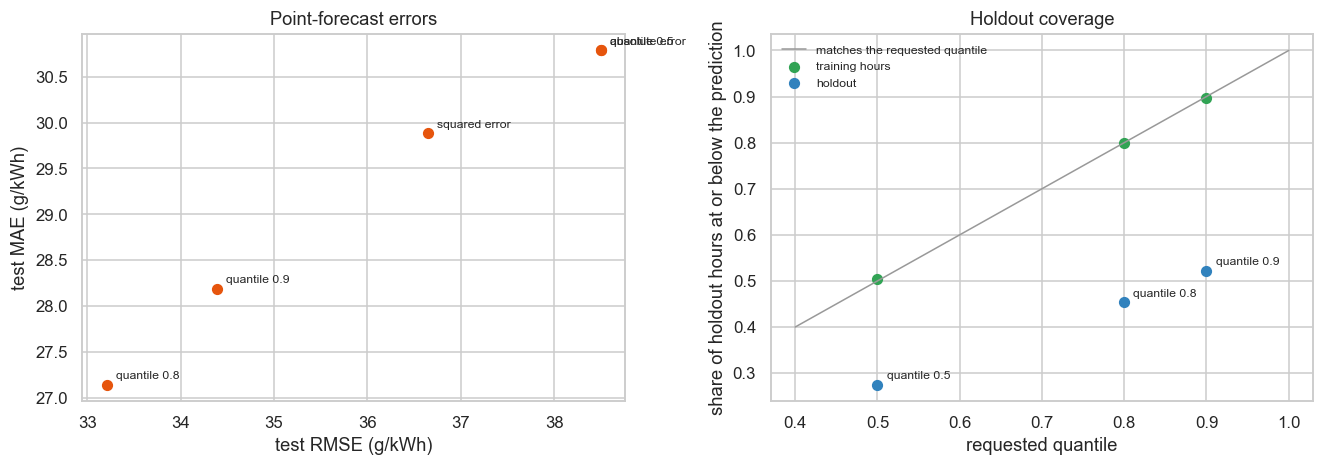

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.4))
axes[0].scatter(table["rmse"], table["mae"], s=40, color="#e6550d")
for _, row in table.iterrows():
    axes[0].annotate(row["loss"], (row["rmse"], row["mae"]), textcoords="offset points", xytext=(6, 4), fontsize=8)
axes[0].set_xlabel("test RMSE (g/kWh)")
axes[0].set_ylabel("test MAE (g/kWh)")
axes[0].set_title("Point-forecast errors")

quantile_rows = table[table["loss"].str.startswith("quantile")].copy()
requested = [0.5, 0.8, 0.9]
axes[1].plot([0.4, 1.0], [0.4, 1.0], color="0.6", lw=1, label="matches the requested quantile")
axes[1].scatter(requested, quantile_rows["coverage_train"], s=40, color="#31a354", label="training hours")
axes[1].scatter(requested, quantile_rows["coverage_holdout"], s=40, color="#3182bd", label="holdout")
for level, (_, row) in zip(requested, quantile_rows.iterrows()):
    axes[1].annotate(row["loss"], (level, row["coverage_holdout"]), textcoords="offset points", xytext=(6, 4), fontsize=8)
axes[1].set_xlabel("requested quantile")
axes[1].set_ylabel("share of holdout hours at or below the prediction")
axes[1].set_title("Holdout coverage")
axes[1].legend(frameon=False, fontsize=8)
fig.tight_layout()

best_point = table.sort_values("mae").iloc[0]
quantile_90 = table.loc[table["loss"] == "quantile 0.9"].iloc[0]
print(
    f"Lowest holdout MAE is {best_point['loss']} at {best_point['mae']:.2f} g/kWh. "
    f"Quantile 0.9 covers {quantile_90['coverage_train']:.2f} of training hours "
    f"and {quantile_90['coverage_holdout']:.2f} of the holdout."
)
